# Exploring the runs

Run the cells top to bottom. Everything comes through `DataLoader`, the same way the
commands get it, so what you see here is what the modelling will see.

If a cell about the data fails, run `uv run limodel check` in the terminal first.

## 1. Load

In [1]:
%load_ext autoreload
%autoreload 2

import os
from pathlib import Path

# work from the project root, so DATA_DIR in .env resolves
if Path.cwd().name == 'notebooks':
    os.chdir(Path.cwd().parent)

import pandas as pd
import matplotlib.pyplot as plt

from limodel import config
from limodel.data_loader import DataLoader

print('data from', config.DATA_DIR.resolve())

runs = DataLoader().load()
print(len(runs), 'runs:', ' '.join(run.run_code for run in runs))

data from /Users/sureshhemal/MSc/Li-Research/data
21 runs: AE AF AG AH AI AJ AK AL AM AN AO AP AQ AR AS AT AU AV AW AX AY


## 2. One run, as objects

A `Run` holds its own settings, its power log, and one reading per tank per minute.
A sample hangs off the reading it was drawn from — most readings have none.

In [2]:
run = {r.run_code: r for r in runs}['AE']

print('membrane      ', run.cem)
print('cell pairs    ', run.cell_pairs)
print('area          ', run.area_cm2, 'cm2')
print('tares         ', run.tare_conc_g, run.tare_dil_g, run.tare_rinse_g, 'g')
print('stack readings', len(run.stack_readings))
print('tank readings ', len(run.tank_readings))
print('samples       ', sum(1 for t in run.tank_readings if t.sample))

membrane       GO-10
cell pairs     10
area           6.0 cm2
tares          96.2 111.5 42.0 g
stack readings 31
tank readings  37
samples        15


In [3]:
# every sample in this run, with the reading it came from
pd.DataFrame([
    {'id': t.sample.id, 'minute': t.minute, 'tank': t.tank,
     'weight_g': t.weight_g, 'li_mg_l': t.sample.li_mg_l, 'mg_mg_l': t.sample.mg_mg_l}
    for t in run.tank_readings if t.sample
])

,id,minute,tank,weight_g,li_mg_l,mg_mg_l
0,AE1,0,conc,2119.7,63.560,2.9740
1,AE3,60,conc,2118.4,93.280,46.3600
2,AE5,120,conc,2115.1,128.400,83.8600
3,AE7,180,conc,2101.5,160.200,118.1000
4,AE9,240,conc,2101.5,218.500,130.0000
5,AE2,0,dil,2117.8,403.100,1657.0000
6,AE4,60,dil,2115.2,361.800,1635.0000
7,AE6,120,dil,2098.2,323.800,1610.0000
8,AE8,180,dil,2061.6,295.300,1596.0000
9,AE10,240,dil,2040.7,261.900,1467.0000


### The same run as JSON

`Run` is a pydantic model, so it can print itself. `JSON(...)` gives a tree you can
fold open; `print(...model_dump_json(indent=2))` gives plain text.

The readings make it long — 585,000 characters for all 17 runs — so exclude them, or
look at one run at a time.

In [ ]:
import json
from IPython.display import JSON
from pydantic import TypeAdapter
from limodel.models import Run

# a foldable tree of one whole run, readings and samples included
JSON(json.loads(run.model_dump_json()), expanded=False)

# other ways to look at it:
#   print(run.model_dump_json(indent=2))                                  plain text
#   print(run.model_dump_json(indent=2, exclude={'stack_readings', 'tank_readings'}))
#   run.model_dump()                                                      a dict
#   TypeAdapter(list[Run]).dump_json(runs, indent=2).decode()             every run

## 3. The settings of every run

One row per run — what was chosen before it started.

In [4]:
pd.DataFrame([
    {'run': r.run_code, 'date': r.run_date, 'cem': r.cem,
     'li_feed': r.li_feed_mg_l, 'mg_feed': r.mg_feed_mg_l,
     'conc_start': f'{r.conc_start_g_l} {r.conc_start_salt}',
     'pairs': r.cell_pairs, 'area': r.area_cm2, 'include': r.include}
    for r in runs
]).set_index('run')

,date,cem,li_feed,mg_feed,conc_start,pairs,area,include
run,,,,,,,,
AE,2026-07-09,GO-10,400.0,2000.0,0.5 LiCl,10,6.0,True
AF,2026-07-11,GO-10,400.0,4000.0,0.5 LiCl,10,6.0,True
AG,2026-07-12,GO-10,400.0,8000.0,0.5 LiCl,10,6.0,True
AH,2026-07-16,GO-10,400.0,2000.0,0.5 LiCl,10,6.0,True
AI,2026-07-16,GO-10,400.0,2000.0,0.5 LiCl,10,6.0,True
AJ,2026-07-22,GO-10,400.0,2000.0,0.5 LiCl,10,6.0,True
AK,2026-07-25,Pristine,400.0,2000.0,0.5 LiCl,10,6.0,True
AL,2026-07-28,Pristine,400.0,2000.0,0.5 LiCl,10,6.0,True
AM,2026-07-31,Pristine,400.0,2000.0,0.5 LiCl,10,6.0,True


## 4. How a run moves

Conductivity says it plainly: the concentrate fills up, the diluate empties.

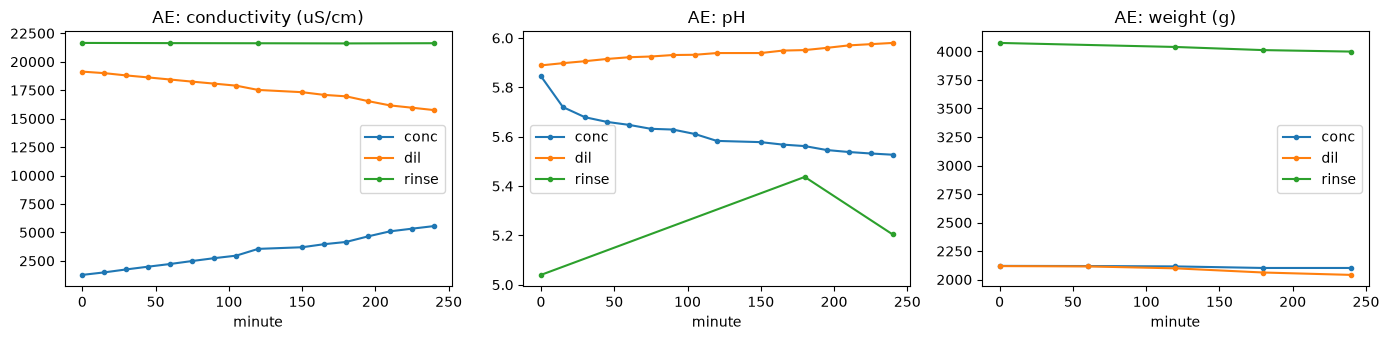

In [5]:
def tank_series(run, tank, column):
    rows = [(t.minute, getattr(t, column)) for t in run.tank_readings
            if t.tank == tank and getattr(t, column) is not None]
    return pd.Series(dict(rows)).sort_index()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, column, label in zip(axes, ['conductivity_us_cm', 'ph', 'weight_g'],
                            ['conductivity (uS/cm)', 'pH', 'weight (g)']):
    for tank in ('conc', 'dil', 'rinse'):
        s = tank_series(run, tank, column)
        if len(s):
            ax.plot(s.index, s.values, marker='o', ms=3, label=tank)
    ax.set_xlabel('minute'); ax.set_title(f'{run.run_code}: {label}'); ax.legend()
plt.tight_layout()

## 5. The chemistry, step by step

This is the chain the modelling will do for every run. Here it is once, in the open,
so the numbers can be checked against the spreadsheet.

Change `run` above to look at a different one.

In [6]:
M_LI, M_MG = 6.94, 24.305      # g/mol

def point(run, tank, minute, ion):
    """(concentration mg/L, volume L) for one tank at one minute."""
    tare = {'conc': run.tare_conc_g, 'dil': run.tare_dil_g, 'rinse': run.tare_rinse_g}[tank]
    for t in run.tank_readings:
        if t.tank == tank and t.minute == minute and t.weight_g and t.sample:
            return getattr(t.sample, f'{ion}_mg_l'), (t.weight_g - tare) / 1000
    return None

moments = sorted({t.minute for t in run.tank_readings
                  if t.tank == 'conc' and t.weight_g and t.sample and t.sample.li_mg_l})
first, last = moments[0], moments[-1]
print('window', first, '->', last, 'minutes')

for ion, M in (('li', M_LI), ('mg', M_MG)):
    (c0, v0), (c1, v1) = point(run, 'conc', first, ion), point(run, 'conc', last, ion)
    print(f'{ion}: {c0} mg/L in {v0:.4f} L  ->  {c1} mg/L in {v1:.4f} L')

window 0 -> 240 minutes
li: 63.56 mg/L in 2.0235 L  ->  218.5 mg/L in 2.0053 L
mg: 2.974 mg/L in 2.0235 L  ->  130.0 mg/L in 2.0053 L


In [7]:
def moles_gained(run, ion, M):
    (c0, v0), (c1, v1) = point(run, 'conc', first, ion), point(run, 'conc', last, ion)
    return (c1 / M * v1 - c0 / M * v0) / 1000      # mol

n_li, n_mg = moles_gained(run, 'li', M_LI), moles_gained(run, 'mg', M_MG)
equivalents = n_li + 2 * n_mg                       # Mg2+ carries two charges

t_li = n_li / equivalents
t_mg = 2 * n_mg / equivalents

li_d0, _ = point(run, 'dil', first, 'li')
mg_d0, v_d0 = point(run, 'dil', first, 'mg')
feed_ratio = (li_d0 / M_LI) / (mg_d0 / M_MG)

P = (t_li / t_mg) / feed_ratio
recovery = n_li * 100 / (li_d0 / M_LI * v_d0 / 1000)

currents = [s.meter_current_ma for s in run.stack_readings if s.meter_current_ma]

print(f'moles into the concentrate   Li {n_li*1000:7.2f} mmol   Mg {n_mg*1000:7.2f} mmol')
print(f'transport numbers            t_Li {t_li:.4f}          t_Mg {t_mg:.4f}')
print(f'feed ratio (molar Li/Mg)     {feed_ratio:.4f}')
print(f'permselectivity              P = {P:.4f}')
print(f'Li recovery                  {recovery:.2f} %')
print(f'current density              {sum(currents)/len(currents)/run.area_cm2:.2f} mA/cm2')
print(f'starting voltage             {run.stack_readings[0].supply_voltage_v} V')

moles into the concentrate   Li   44.60 mmol   Mg   10.48 mmol
transport numbers            t_Li 0.6803          t_Mg 0.3197
feed ratio (molar Li/Mg)     0.8520
permselectivity              P = 2.4982
Li recovery                  38.27 %
current density              12.12 mA/cm2
starting voltage             16.0 V


For AE this should print **t_Li 0.6803, P 2.4982, recovery 38.27 %** — the same numbers
as the spreadsheet. If it does, the chain is right.

## 6. Every run in one table

The same chain over all of them: the settings on the left, the outcomes on the right.
This is the table the polynomial gets fitted to.

In [8]:
def summarise(run):
    moments = sorted({t.minute for t in run.tank_readings
                      if t.tank == 'conc' and t.weight_g and t.sample and t.sample.li_mg_l})
    if len(moments) < 2:
        return None

    a, b = moments[0], moments[-1]
    if not (point(run, 'dil', a, 'li') and point(run, 'conc', b, 'mg')):
        return None

    def gained(ion, M):
        (c0, v0), (c1, v1) = point(run, 'conc', a, ion), point(run, 'conc', b, ion)
        return (c1 / M * v1 - c0 / M * v0) / 1000

    n_li, n_mg = gained('li', M_LI), gained('mg', M_MG)
    eq = n_li + 2 * n_mg
    li_d0, _ = point(run, 'dil', a, 'li')
    mg_d0, v_d0 = point(run, 'dil', a, 'mg')
    ratio = (mg_d0 / M_MG) / (li_d0 / M_LI)
    currents = [s.meter_current_ma for s in run.stack_readings if s.meter_current_ma]

    return {
        'run': run.run_code,
        'membrane': run.cem,
        'conc_start': f'{run.conc_start_g_l} {run.conc_start_salt}',
        'J_ma_cm2': round(sum(currents) / len(currents) / run.area_cm2, 1),
        'R_mg_per_li': round(ratio, 2),
        'hours': round((b - a) / 60, 1),
        't_li': round(n_li / eq, 4),
        'P': round((n_li / eq) / (2 * n_mg / eq) * (mg_d0 / M_MG) / (li_d0 / M_LI), 3),
        'recovery_pct': round(n_li * 100 / (li_d0 / M_LI * v_d0 / 1000), 1),
        'v_start': run.stack_readings[0].supply_voltage_v,
    }

table = pd.DataFrame([r for r in (summarise(run) for run in runs) if r]).set_index('run')
table

,membrane,conc_start,J_ma_cm2,R_mg_per_li,hours,t_li,P,recovery_pct,v_start
run,,,,,,,,,
AE,GO-10,0.5 LiCl,12.1,1.17,4.0,0.6803,2.498,38.3,16.00
AF,GO-10,0.5 LiCl,12.1,2.39,4.0,0.3658,1.376,18.3,15.94
AG,GO-10,0.5 LiCl,12.1,4.65,4.0,0.1321,0.707,6.2,13.90
AH,GO-10,0.5 LiCl,6.1,1.45,8.0,0.6220,2.388,36.6,10.55
AI,GO-10,0.5 LiCl,6.1,1.39,8.0,0.5935,2.032,37.7,10.22
AJ,GO-10,0.5 LiCl,3.1,1.31,16.0,0.5603,1.668,39.7,6.23
AK,Pristine,0.5 LiCl,12.1,1.30,4.0,0.1165,0.171,6.1,14.57
AL,Pristine,0.5 LiCl,6.0,1.39,8.0,0.1689,0.282,12.2,8.25
AM,Pristine,0.5 LiCl,3.0,1.41,16.0,0.1241,0.200,7.7,5.40


## 7. What the shape looks like

Left: P against current density, for the runs at a low Mg/Li ratio.
Right: P against Mg/Li ratio, for the runs at 12 mA/cm2.

These two lines are the whole design — nothing was run off-axis, so the middle of the
square is empty.

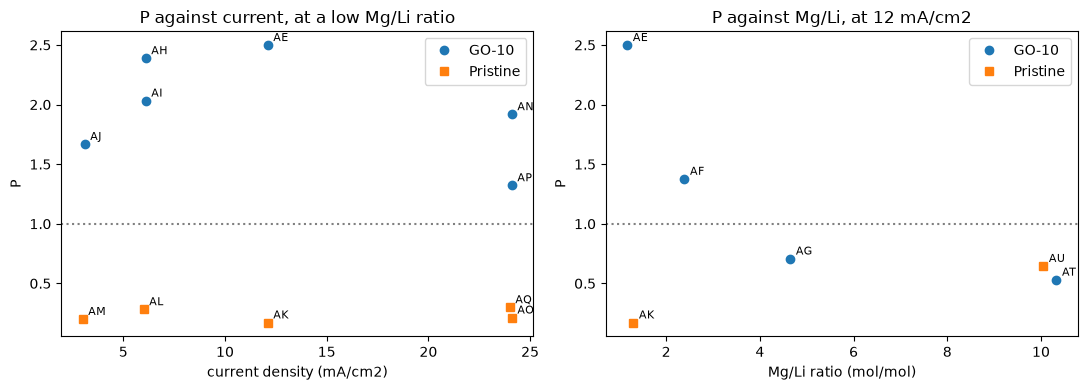

In [9]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))

for membrane, marker in (('GO-10', 'o'), ('Pristine', 's')):
    arm = table[(table.membrane.str.lower() == membrane.lower()) & (table.R_mg_per_li < 2)]
    left.plot(arm.J_ma_cm2, arm.P, marker, label=membrane)
    for code_, row in arm.iterrows():
        left.annotate(code_, (row.J_ma_cm2, row.P), fontsize=8,
                      textcoords='offset points', xytext=(4, 3))
left.axhline(1, ls=':', c='grey')
left.set_xlabel('current density (mA/cm2)'); left.set_ylabel('P'); left.legend()
left.set_title('P against current, at a low Mg/Li ratio')

arm = table[(table.J_ma_cm2 > 11) & (table.J_ma_cm2 < 13)]
for membrane, marker in (('GO-10', 'o'), ('Pristine', 's')):
    part = arm[arm.membrane.str.lower() == membrane.lower()]
    right.plot(part.R_mg_per_li, part.P, marker, label=membrane)
    for code_, row in part.iterrows():
        right.annotate(code_, (row.R_mg_per_li, row.P), fontsize=8,
                       textcoords='offset points', xytext=(4, 3))
right.axhline(1, ls=':', c='grey')
right.set_xlabel('Mg/Li ratio (mol/mol)'); right.set_ylabel('P'); right.legend()
right.set_title('P against Mg/Li, at 12 mA/cm2')

plt.tight_layout()

## 8. Readings that cannot be true

A tank cannot weigh less than the empty tank, and it cannot change by a large share of
its own contents between two readings. Both rules use the run's own numbers, so they
work on a run nobody has done yet.

In [10]:
suspect = []
for run in runs:
    tares = {'conc': run.tare_conc_g, 'dil': run.tare_dil_g, 'rinse': run.tare_rinse_g}
    for tank, tare in tares.items():
        weights = [(t.minute, t.weight_g) for t in run.tank_readings
                   if t.tank == tank and t.weight_g]
        weights.sort()
        level = pd.Series([w for _, w in weights]).median()
        for minute, w in weights:
            if w <= tare:
                suspect.append((run.run_code, tank, minute, w, 'at or below the tare'))
        for (m0, a), (m1, b) in zip(weights, weights[1:]):
            if abs(b - a) > 0.10 * level:
                suspect.append((run.run_code, tank, m1, b,
                                f'{b - a:+.0f} g from the reading before, {abs(b-a)/level:.0%} of the tank'))

pd.DataFrame(suspect, columns=['run', 'tank', 'minute', 'weight_g', 'why'])

,run,tank,minute,weight_g,why
0,AJ,conc,60,2098.9,"+1889 g from the reading before, 94% of the tank"
1,AU,rinse,240,13.8,at or below the tare
2,AU,rinse,240,13.8,"-4012 g from the reading before, 99% of the tank"
3,AV,dil,240,127.2,at or below the tare
4,AV,dil,240,127.2,"-2009 g from the reading before, 94% of the tank"


## 9. What the command does

The same load, through the analyzer.

In [15]:
from limodel.analyzer import Analyzer, Journal

analysis = Analyzer(DataLoader(), Journal()).analyze()
print(analysis.used)

[Run(run_code='AE', series='new_set_mg', run_date=datetime.date(2026, 7, 9), cem='GO-10', aem='AR 204', li_feed_mg_l=400.0, mg_feed_mg_l=2000.0, licl_g_l=2.44, mgcl2_6h2o_g_l=None, conc_start_salt='LiCl', conc_start_g_l=0.5, rinse_salt='Na2SO4', rinse_wt_pct=2.0, set_current_ma=None, flow_l_min=0.2, area_cm2=6.0, cell_pairs=10, tare_conc_g=96.2, tare_dil_g=111.5, tare_rinse_g=42.0, include=True, notes=None, stack_readings=[StackReading(run_code='AE', minute=0, supply_voltage_v=16.0, supply_current_a=0.081, meter_voltage_v=15.93, meter_current_ma=72.1, notes=None, id='AE:0', run_id='AE'), StackReading(run_code='AE', minute=10, supply_voltage_v=15.44, supply_current_a=0.082, meter_voltage_v=15.4, meter_current_ma=72.4, notes=None, id='AE:10', run_id='AE'), StackReading(run_code='AE', minute=15, supply_voltage_v=15.12, supply_current_a=0.082, meter_voltage_v=15.08, meter_current_ma=72.5, notes=None, id='AE:15', run_id='AE'), StackReading(run_code='AE', minute=20, supply_voltage_v=14.78, s